Dataset created successfully
Total samples: 200

Estimated Means:
[4.88 9.97]

Estimated Variances:
[0.81 2.23]

Mixing Weights:
[0.49 0.51]

Log-Likelihood:
-444.86


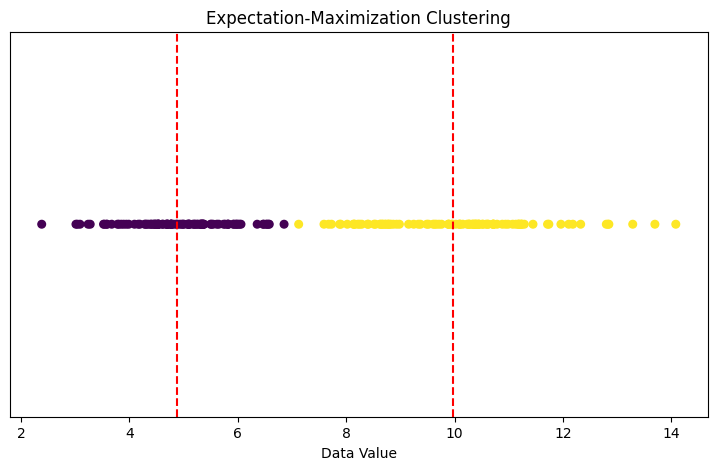


New Sample Predictions:
Sample 4.5 belongs to Cluster 0
Sample 9.5 belongs to Cluster 1
Sample 12.0 belongs to Cluster 1

EM Algorithm completed successfully.


In [10]:

# Implementation of Expectation-Maximization Algorithm

# Step 1: Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

# Step 2: Generate sample dataset
np.random.seed(42)

data1 = np.random.normal(5, 1, 100)
data2 = np.random.normal(10, 1.5, 100)

X = np.concatenate([data1, data2]).reshape(-1, 1)

print("Dataset created successfully")
print("Total samples:", len(X))

# Step 3: Create the Gaussian Mixture Model
gmm = GaussianMixture(
    n_components=2,
    random_state=42,
    n_init=5
)

# Step 4: Fit the model using the EM algorithm
gmm.fit(X)

# Step 5: Predict cluster labels
labels = gmm.predict(X)

# Step 6: Display estimated parameters
print("\nEstimated Means:")
print(np.round(gmm.means_.flatten(), 2))

print("\nEstimated Variances:")
print(np.round(gmm.covariances_.flatten(), 2))

print("\nMixing Weights:")
print(np.round(gmm.weights_, 2))

print("\nLog-Likelihood:")
print(round(gmm.score(X) * len(X), 2))

# Step 7: Visualize the clusters
plt.figure(figsize=(9, 5))

plt.scatter(
    X[:, 0],
    np.zeros(len(X)),
    c=labels,
    cmap="viridis",
    s=30,
    label="Data Samples"
)

for mean in gmm.means_.flatten():
    plt.axvline(
        mean,
        color="red",
        linestyle="--"
    )

plt.xlabel("Data Value")
plt.yticks([])
plt.title("Expectation-Maximization Clustering")
plt.show()

# Step 8: Predict clusters for new samples
new_samples = np.array([[4.5], [9.5], [12.0]])
predictions = gmm.predict(new_samples)

print("\nNew Sample Predictions:")
for sample, cluster in zip(new_samples.flatten(), predictions):
    print(f"Sample {sample} belongs to Cluster {cluster}")

print("\nEM Algorithm completed successfully.")
